# Milestone 7: operating cases, sensitivities and CO2 per tonne of DRI

This notebook reads the stored results of

- `scripts/compare_cases.py` (REDUCTOR cases A–E and the Fig. 10 sweep on 50, 100 and 200 cells),
- `scripts/run_cooling_continuation.py` (cooling-flow sweep by continuation, 200 cells),
- `scripts/run_sensitivity.py` (bustle temperature, bustle flow and pellet diameter, 50 and 200 cells),

and shows the figures made by `scripts/plot_m7.py`. Re-running everything takes about two hours on
6 cores. Inputs: `data/furnace_cases.yaml`, `data/sensitivity.yaml`, `data/emissions.yaml`,
`data/grid_intensity.yaml`; references: `tests/data/` (sources in `data/SOURCES.md`).
Unconverged runs appear as NaN: they are not solutions.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import json

import compare_cases as cc
import numpy as np
import pandas as pd
import run_sensitivity as rs
from IPython.display import Image, display

pd.set_option("display.float_format", lambda v: f"{v:.4g}")

## 1. REDUCTOR cases B–E: does the 1D model predict the same *changes*?

Each case differs from case A only in the operating conditions of Table 1 (no parameter is
adjusted). Changes from case A, model vs REDUCTOR; case D (burden at 1200 °C) lies outside the
temperature range of the kinetic data and is an extrapolation.

In [2]:
ref = cc.reference_cases()
rows = []
for cells in (50, 100, 200):
    res = cc.load_results(cells)
    for c in "BCDE":
        for k in cc.OUTPUTS:
            rows.append({"cells": cells, "case": c, "output": k,
                         "model change": res[c][k] - res["A"][k],
                         "REDUCTOR change": ref[c][k] - ref["A"][k]})
changes = pd.DataFrame(rows).pivot_table(index=["case", "output"], columns="cells",
                                         values="model change", dropna=False)
changes["REDUCTOR"] = [ref[c][k] - ref["A"][k] for c, k in changes.index]
changes

cells                     50       100       200  REDUCTOR
case output                                               
B    dri_T            -194.3    -208.7      -221       -95
     gud            -0.01501  -0.01222 -0.009411         0
     metallization    -6.961    -5.668    -4.366       0.4
     top_gas_T        -5.431    -4.245    -3.263        -3
C    dri_T             68.32     63.33     56.18       141
     gud              0.1287     0.131    0.1324      0.14
     metallization     1.001     2.017      2.86      -0.1
     top_gas_T         40.83     40.55     40.97        50
D    dri_T             120.2     84.24    -27.02        69
     gud             0.01173   0.01365   0.01644      0.01
     metallization     5.443     6.334     7.627       0.8
     top_gas_T         429.4     435.8     456.1       462
E    dri_T            -12.12    -20.64    -32.77       142
     gud           -0.001918 1.028e-06  0.002789     -0.01
     metallization     5.443     6.334     7.627       6.7
     top_gas_T         11.71     12.41     13.37         9

## 2. Cooling-gas flow (Fig. 10 of the paper)

In [3]:
fig10 = cc.reference_fig10()
tab = pd.DataFrame({"REDUCTOR": fig10})
for cells in (50, 100, 200):
    res = cc.load_results(cells)
    tab[f"{cells} cells"] = [res[f"B_cool{f:g}"]["metallization"] for f in cc.SWEEP]
tab.index.name = "cooling flow (mol/s)"
tab

,REDUCTOR,50 cells,100 cells,200 cells
cooling flow (mol/s),,,,
500,93.27,94.55,93.66,92.37
600,94.57,96.23,96.06,95.56
700,93.67,87.6,88,88.01
800,92.2,77.3,76.33,76.05


In [4]:
cont = json.loads((ROOT / "results" / "cases" / "cooling_continuation_200cells.json").read_text())
pd.DataFrame(cont)[["direction", "cooling_flow", "converged", "outer_iterations",
                    "metallization", "dri_T_C", "top_gas_T_C"]]

,direction,cooling_flow,converged,outer_iterations,metallization,dri_T_C,top_gas_T_C
0,up,500,True,23,0.9237,291,360.9
1,up,525,True,23,0.9317,251.4,361.5
2,up,550,True,24,0.9397,210.2,362.1
3,up,575,True,27,0.9477,167.2,362.7
4,up,600,True,34,0.9556,122.3,363.3
5,up,625,True,181,0.9623,76.69,363.8
6,up,650,True,49,0.9383,70.01,362
7,up,675,True,47,0.9092,70,359.8
8,up,700,True,63,0.8801,70,357.7
9,up,725,True,162,0.8506,70,355.5


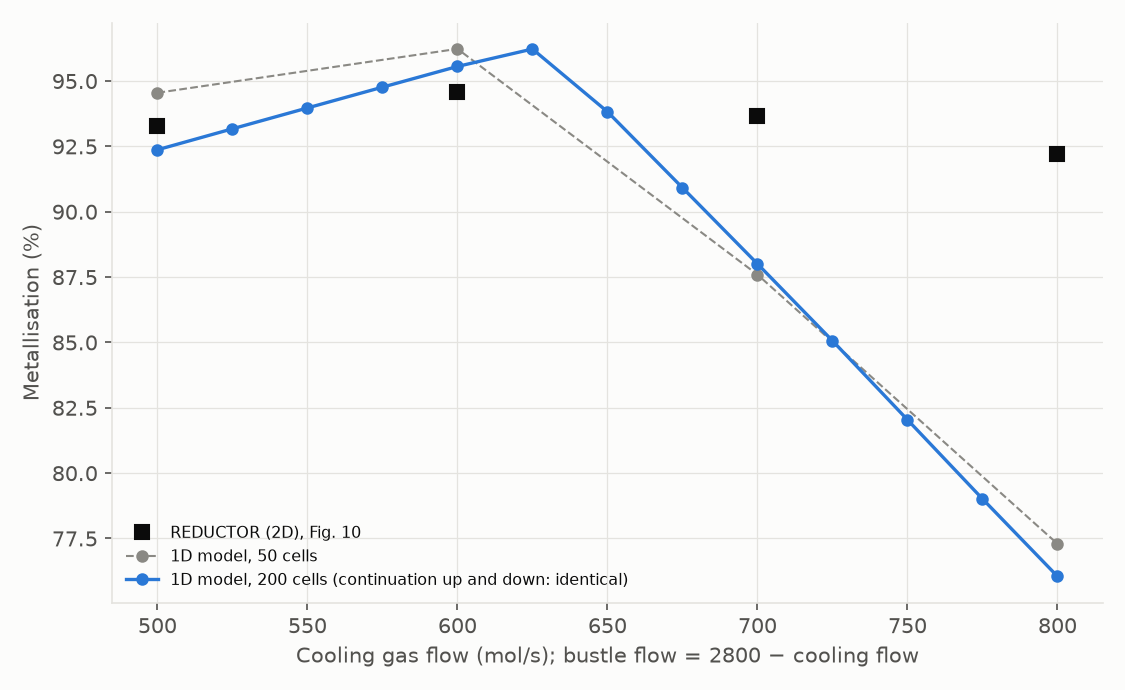

In [5]:
display(Image(str(ROOT / "figures" / "m7_cooling_sweep.png")))

Below about 600 mol/s the burden is cooled in a thin front at the outlet and leaves
hot; above about 750 mol/s the cooling gas cools the whole lower cone and the DRI leaves at the
cooling-gas temperature (70 °C), with wüstite reduction stalling in the cold cone. In between, the
heat-capacity flows of gas and burden in the cone are nearly equal, the front can sit anywhere
in the cone, and the coupled iteration does not converge on 200 cells (it cycles between states;
damped, Anderson-accelerated and pseudo-transient iterations were tried). REDUCTOR distributes
the cooling gas in 2D and shows a much milder decline.

## 3. One-at-a-time sensitivities

In [6]:
sens = []
for cells in (50, 200):
    for r in rs.load(cells):
        sens.append({"cells": cells, **r})
sens = pd.DataFrame(sens)
outs = ["metallization", "h2_consumption_kg_per_t", "co2_south_africa_t_per_t", "dri_T_C"]
sens.loc[~sens["converged"], outs] = np.nan
sens.pivot_table(index=["input", "value"], columns="cells",
                 values=["metallization", "co2_south_africa_t_per_t"], dropna=False)

co2_south_africa_t_per_t       metallization       
cells                                         50    200           50     200
input              value                                                    
bustle_flow        0.01                       NaN   NaN           NaN    NaN
                   0.011                      NaN   NaN           NaN    NaN
                   0.012                      NaN   NaN           NaN    NaN
                   0.013                      NaN   NaN           NaN    NaN
                   0.014                      NaN   NaN           NaN    NaN
                   0.015                      NaN   NaN           NaN    NaN
                   1088                       NaN   NaN           NaN    NaN
                   1115                       NaN   NaN           NaN    NaN
                   1142                       NaN   NaN           NaN    NaN
                   1169                       NaN   NaN           NaN    NaN
                   1196                       NaN   NaN           NaN    NaN
                   1223                       NaN   NaN           NaN    NaN
                   2000                     2.031 1.958        0.7811 0.7416
                   2086                     2.129 2.061        0.8228 0.7868
                   2172                      2.24 2.178        0.8701 0.8384
                   2258                     2.359 2.308          0.92 0.8947
                   2344                     2.489 2.451        0.9735 0.9552
                   2430                       NaN 2.565           NaN      1
bustle_temperature 0.01                       NaN   NaN           NaN    NaN
                   0.011                      NaN   NaN           NaN    NaN
                   0.012                      NaN   NaN           NaN    NaN
                   0.013                      NaN   NaN           NaN    NaN
                   0.014                      NaN   NaN           NaN    NaN
                   0.015                      NaN   NaN           NaN    NaN
                   1088                     1.936 1.883        0.7197 0.6889
                   1115                     2.115 2.037        0.8062 0.7646
                   1142                     2.278 2.195        0.8812 0.8393
                   1169                     2.476 2.434        0.9703 0.9502
                   1196                     2.556 2.556             1      1
                   1223                     2.573   NaN             1    NaN
                   2000                       NaN   NaN           NaN    NaN
                   2086                       NaN   NaN           NaN    NaN
                   2172                       NaN   NaN           NaN    NaN
                   2258                       NaN   NaN           NaN    NaN
                   2344                       NaN   NaN           NaN    NaN
                   2430                       NaN   NaN           NaN    NaN
pellet_diameter    0.01                     2.439 2.385        0.9542 0.9279
                   0.011                    2.436 2.383        0.9526 0.9271
                   0.012                    2.432 2.381        0.9509 0.9263
                   0.013                    2.429 2.379        0.9491 0.9253
                   0.014                    2.425 2.378        0.9474 0.9245
                   0.015                    2.421 2.376        0.9456 0.9237
                   1088                       NaN   NaN           NaN    NaN
                   1115                       NaN   NaN           NaN    NaN
                   1142                       NaN   NaN           NaN    NaN
                   1169                       NaN   NaN           NaN    NaN
                   1196                       NaN   NaN           NaN    NaN
                   1223                       NaN   NaN           NaN    NaN
                   2000                       NaN   NaN           NaN    NaN
                   20

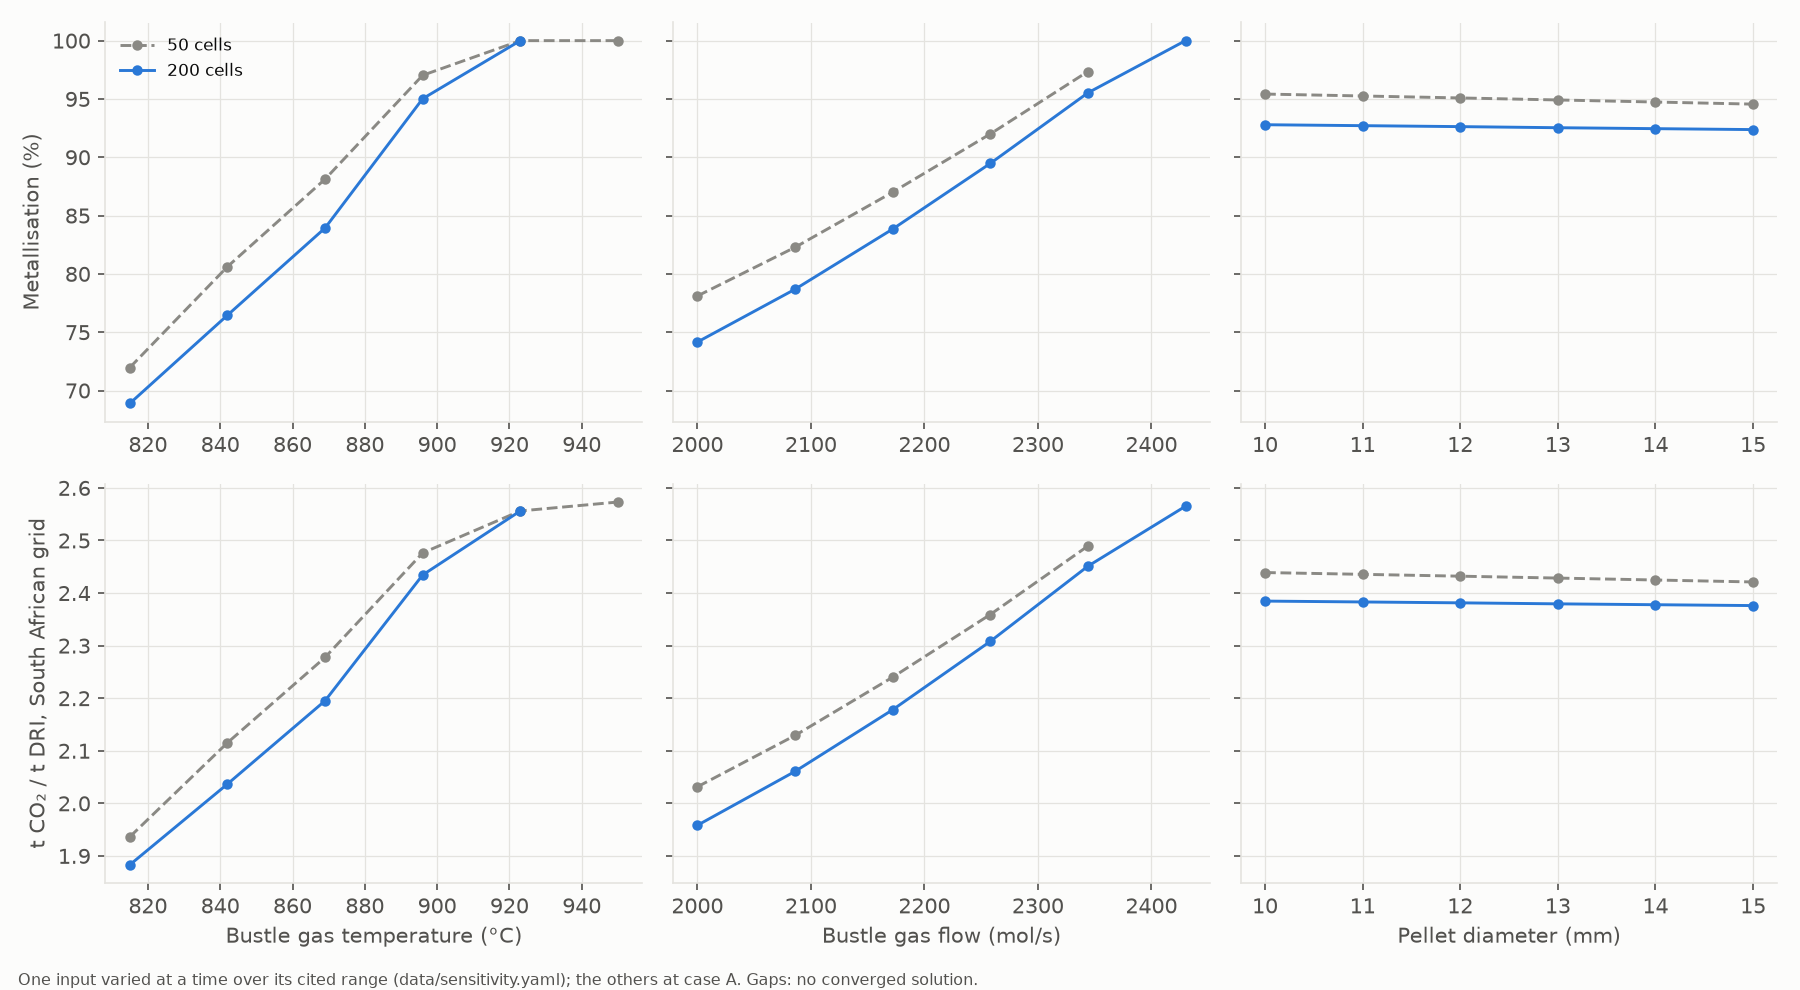

In [7]:
display(Image(str(ROOT / "figures" / "m7_sensitivity.png")))

The bustle gas temperature and flow dominate: over their cited ranges metallisation
spans about 0.7 to 1. Pellet diameter (10–15 mm) moves it by less than 0.01 in this model,
because wüstite reduction here is limited by heat and gas supply rather than by diffusion
in the pellet; with the kinetics of one pellet type this should not be generalised. More
metallisation removes more oxygen, so H₂ and CO₂ per tonne of DRI rise with it.

## 4. Electricity and CO₂ per tonne of DRI

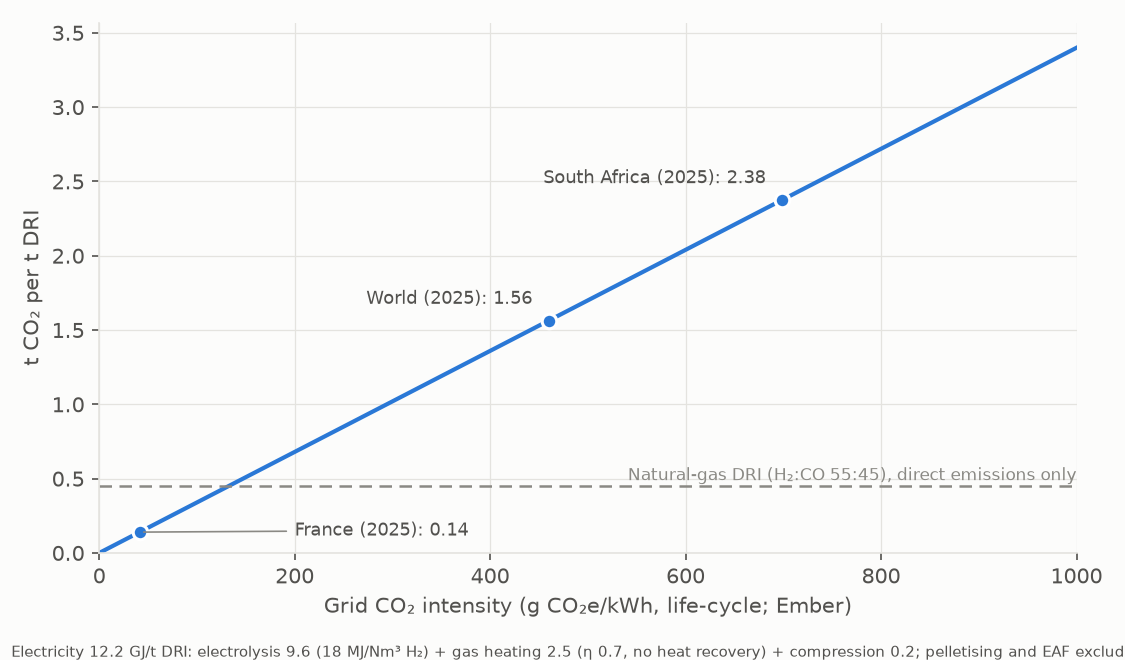

In [8]:
display(Image(str(ROOT / "figures" / "m7_co2.png")))

In [9]:
from shaftsim import emissions as em
from shaftsim import operating as op
from shaftsim import scenario as sc

base = sc.load_base(ROOT / "data")
res = sc.run_scenario(base, op.conditions_of(base.case), 50)  # ~15 s; the figure uses 200 cells
e = res.energy
print(f"case A, 50 cells: electricity {e.total / 1e6:.2f} GJ/t DRI "
      f"(electrolysis {e.electrolysis / 1e6:.2f}, heating {e.heating / 1e6:.2f}, "
      f"compression {e.compression / 1e6:.2f})")
for g in base.emissions.grids.values():
    co2 = em.co2_per_dri(e, g.value)
    print(f"  {g.name:13s} {g.g_per_kWh:5.0f} g/kWh ({g.year}): {co2:.2f} t CO2/t DRI")
t20_file = ROOT / "tests" / "data" / "reference_energy_marsigny2025_thesis_t20.csv"
t20 = pd.read_csv(t20_file, comment="#")
t20

case A, 50 cells: electricity 12.47 GJ/t DRI (electrolysis 9.78, heating 2.49, compression 0.20)
  South Africa    699 g/kWh (2025): 2.42 t CO2/t DRI
  World           460 g/kWh (2025): 1.59 t CO2/t DRI
  France           41 g/kWh (2025): 0.14 t CO2/t DRI


,key,value,description
0,metallization_pct,93.3,metallisation (%)
1,compression_GJ_per_t,0.25,gas compression
2,heating_GJ_per_t,2.28,gas heating (no reforming in case A)
3,electrolysis_GJ_per_t,9.73,water electrolysis
4,total_GJ_per_t,12.26,total


The model's electrolysis demand matches the authors' gas-loop model (Table 20 of the
thesis) because both follow from the H₂ consumed; the heating term here has no heat recovery
and is an upper bound. On South Africa's grid, hydrogen DRI emits roughly five times the direct
emissions of natural-gas DRI; it needs a supply below about 130 g CO₂e/kWh to do better. The
natural-gas figure excludes upstream methane and electricity, so the true break-even is
somewhat higher. Details and limitations: `docs/validation.md`, Milestone 7.